<img src="logo.png" alt="Vegeta" width="240">

# Svarog remote — welding at 20 m with many lasers crossing at one point

**The question.** A machine that cannot be stopped needs a weld. Can N kilowatt-class lasers, each in its own head, be
focused on **one point 20 m away** and weld there — and what does it take? The answer is built from first principles:
the Gaussian beam budget (what beam a head must send to make a welding spot at 20 m), the real singlet optics of a head
(spherical aberration, astigmatism, and the plane-parallel plate as the compensator), the spot that actually lands on
the target (an exact ray trace of the head and the Fraunhofer sum over its exit pupil), the incoherent sum of N such
spots with pointing errors, the geometry of N heads crossing at one point on a moving target, and Rosenthal's weld
pool. First for 2 heads, then for 10. Nothing here runs longer than a few seconds.

**Two problems named up front.** *Spherical aberration*: rays through the centre and the edge of a lens focus at
different distances. *Astigmatism*: two perpendicular directions focus at different distances, two line foci instead of
a point. Both are measured on the traced rays of real stock lenses, not estimated, and the plane-parallel plate is
tried against both: by its thickness in the converging beam (it overcorrects spherical aberration) and by its tilt (it
adds astigmatism of a chosen axis and amount, which can cancel somebody else's). The ray trace is the judge; the
closed-form formulas explain what it finds.

**The physics is in `designs/svarog_remote.py`**: the Gaussian budget, a small three-dimensional ray tracer (spheres
and planes, tilted at will, Snell in vector form, optical path along the ray), the pupil wavefront and the focal spot,
the ring geometry, Rosenthal's point source and the catalogue of parts.

**Its contract** is declared in `workflows/flow.py` (`flow.notebook("46_svarog_remote", …)`): nothing to take, one file
to give (`designs/data/svarog_remote.json`, the numbers of the verdict). The gate below checks it; the last cell checks
the file was written.

In [1]:
# DEBUG: test the notebook end to end before the full run. Nothing here is mocked (no FEA, no CFD): the switch is kept
# for the common header.
DEBUG = False
from vegeta import mock
DEBUG = mock.setup(DEBUG)

## 1. Prerequisites

The gate: the packages on this machine and the file this notebook promises.

In [2]:
import json, math, os, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vegeta import yanus
sys.path.insert(0, "designs")
import svarog_remote as sr

pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 230); pd.set_option("display.max_columns", 40)
OUT = Path("output/46_svarog_remote"); OUT.mkdir(parents=True, exist_ok=True)
T_START = time.time()

GATE = yanus.enter("46_svarog_remote", debug=DEBUG)
display(GATE.table())

L = 20.0                       # the standoff, m
LAM = 1.070e-6                 # the fibre laser's wavelength, m
HEAD_POWER = 1000.0            # W per head
REPORT = {"standoff_m": L, "wavelength_m": LAM, "head_power_W": HEAD_POWER}

""


## 2. The budget: what spot welds, what beam makes it at 20 m

Welding steel with a 1 µm laser needs a power density of about **10⁵ W/cm² for conduction welding** and about
**10⁶ W/cm² for a keyhole** (the usual thresholds; the exact number depends on the alloy, the spot and the speed). A
Gaussian spot of 1/e² radius $w_0$ carrying $P$ has the peak density $I_0 = 2P / (\pi w_0^2)$: one kilowatt in a
0.5 mm radius gives $2.5 \times 10^5$ W/cm², conduction welding; ten kilowatts in the same spot, $2.5 \times 10^6$,
a keyhole.

A head that sends a beam of 1/e² radius $w_{in}$ converging on the target $L$ away makes a waist there of
$$w_0 = \frac{M^2 \lambda L}{\pi w_{in}} = \frac{\mathrm{BPP} \cdot L}{w_{in}}, \qquad z_R = \frac{\pi w_0^2}{M^2 \lambda}.$$
The beam quality $M^2$ (or the beam parameter product BPP $= M^2 \lambda / \pi$) multiplies the spot directly: the
budget is BPP × standoff / aperture. Three candidate sources, each with the head radius it needs for a 0.5 mm waist at
20 m and the spot it makes from a 20 mm head radius (a 2–3 inch lens):

,P [W],λ [nm],M²,BPP [mm·mrad],head radius for w0 = 0.5 mm [mm],lens Ø for that (1.5 w) [mm],w0 from a 20 mm head radius [mm],z_R [m],I0 per head [W/cm²],source
laser,,,,,,,,,,
IPG YLR-1000-SM,1000.0,1070.0,1.1,0.37,15.0,45,0.37,0.37,4.5e+05,"IPG YLR datasheet: single mode, M² < 1.1, HLC-8 fibre connector, 5 mm collimator"
Raycus RFL-C1000 (50 µm),1000.0,1080.0,4.4,1.51,60.5,182,1.51,1.51,2.8e+04,"multimode 50 µm delivery fibre, BPP ≈ 1.5 mm·mrad (M² ≈ 4.4)"
blue diode 450 nm 200 W,200.0,450.0,60.0,8.59,343.8,1031,8.59,8.59,1.7e+02,"fibre-coupled diode stack, 100–200 µm fibre, BPP ≈ 8 mm·mrad"


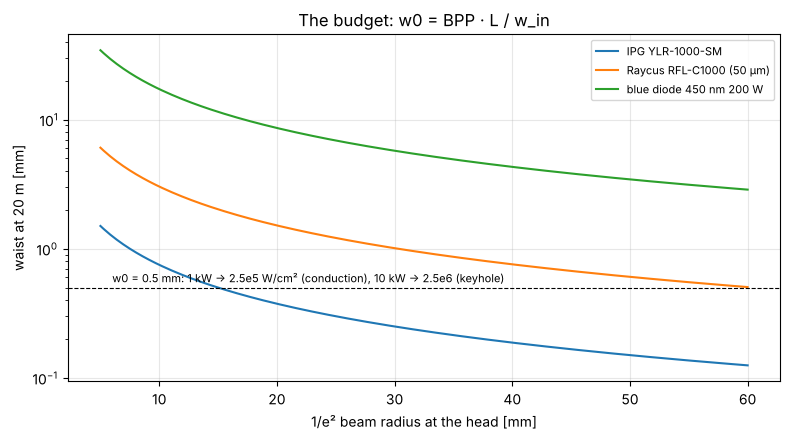

The single-mode fibre laser needs a 14 mm beam radius (a 2" lens); the multimode one a 55 mm radius (a 6" lens); the blue diode stack is out of the question at this distance.


In [3]:
rows = []
for las in sr.LASERS.values():
    need = sr.head_radius_for(las, 0.5e-3, L)
    got = sr.spot_at(las, 0.020, L)
    rows.append({"laser": las.name, "P [W]": las.power_W, "λ [nm]": las.wavelength_m * 1e9, "M²": las.M2, "BPP [mm·mrad]": round(las.bpp_mm_mrad, 2),
                 "head radius for w0 = 0.5 mm [mm]": round(need * 1e3, 1), "lens Ø for that (1.5 w) [mm]": round(3 * need * 1e3),
                 "w0 from a 20 mm head radius [mm]": round(got["w0_mm"], 2), "z_R [m]": round(got["zR_m"], 2),
                 "I0 per head [W/cm²]": f"{got['I0_W_cm2']:.2g}", "source": las.source})
display(pd.DataFrame(rows).set_index("laser"))

w_in = np.linspace(5e-3, 60e-3, 200)
fig, ax = plt.subplots(figsize=(8, 4.5))
for las in sr.LASERS.values():
    ax.plot(w_in * 1e3, [sr.spot_at(las, w, L)["w0_mm"] for w in w_in], label=las.name)
ax.axhline(0.5, color="k", ls="--", lw=0.8); ax.text(6, 0.55, "w0 = 0.5 mm: 1 kW → 2.5e5 W/cm² (conduction), 10 kW → 2.5e6 (keyhole)", fontsize=8)
ax.set(xlabel="1/e² beam radius at the head [mm]", ylabel="waist at 20 m [mm]", yscale="log", title="The budget: w0 = BPP · L / w_in")
ax.grid(alpha=0.3); ax.legend(fontsize=8); plt.tight_layout(); fig.savefig(OUT / "budget.png", dpi=110); plt.show()
print("The single-mode fibre laser needs a 14 mm beam radius (a 2\" lens); the multimode one a 55 mm radius (a 6\" lens);",
      "the blue diode stack is out of the question at this distance.")

## 3. The head: a Galilean expander that also focuses

The laser's own collimator sends a 5 mm beam ($w_{in}$ = 2.5 mm). The head is a **Galilean expander** — a negative
lens L1 and a positive lens L2 — magnifying it ×6 to ×10, and it focuses without a third lens: lengthening the lens
spacing beyond $f_1 + f_2$ by $\delta = f_2^2 / L$ puts the output focus at $L$ (for $f_2$ = 750 mm and 20 m, 28 mm:
the focus knob is a few centimetres of travel of one lens, and it reaches from 10 m to infinity).

Two things decide the spot before any aberration: **how much of the Gaussian the lens clips** (a 2" lens has a 46 mm
clear aperture; a beam of 1/e² radius $w$ clipped at radius $a$ loses $e^{-2a^2/w^2}$ of its power and, worse,
$1 - (1 - e^{-a^2/w^2})^2$ of its peak at the focus — at $a = 1.15 w$ the peak is down 43 %) and **the f-number of
L2**: a plano-convex singlet's spherical aberration grows as the fourth power of the beam height over the lens, so a
short L2 that fits a compact head ruins the spot. Everything below is the exact ray trace of thick stock lenses, the
wavefront over the exit pupil, and the spot at 20 m from its Fraunhofer transform (the focus of the head is the
Fourier plane of its exit pupil), the best focus found by a short scan.

### 3.1 Magnification and aperture

In [4]:
D_IN, W_IN = 6e-3, 2.5e-3                 # the launch extent and the 1/e² radius of the laser's 5 mm beam
APERTURES = {'2" lens (CA 46 mm)': (0.0508, 0.046), '3" lens (CA 70 mm)': (0.0762, 0.070)}
rows, SPOTS = [], {}
for ap_name, (D2, CA) in APERTURES.items():
    for mag in (6, 8, 10, 12):
        g, lay = sr.galilean(-0.75 / mag, 0.75, D2, L=L, D_in=D_IN)
        pw = sr.pupil_wavefront(g, D_IN, W_IN, L, D_ap=CA)
        best = sr.best_focus(pw, LAM, L, HEAD_POWER, span=0.75, n=7)
        SPOTS[(ap_name, mag)] = (g, lay, pw, best)
        rows.append({"aperture": ap_name, "×": mag, "beam radius at L2 [mm]": round(pw["w_beam"] * 1e3, 1), "a / w": round(CA / 2 / pw["w_beam"], 2),
                     "power through [%]": round(100 * pw["throughput"], 1), "wavefront rms [nm]": round(pw["rms_m"] * 1e9), "Strehl (Maréchal)": round(sr.strehl(pw, LAM), 3),
                     "spot r86 at 20 m [mm]": round(best["r86_mm"], 3), "peak [W/cm² per kW]": f"{best['peak_W_cm2']:.3g}", "best focus shift [m]": best["defocus_m"],
                     "L1 f [mm]": round(-750 / mag, 1), "spacing [mm]": round(lay["spacing"] * 1e3, 1), "δ [mm]": round(lay["delta"] * 1e3, 1)})
MAG = pd.DataFrame(rows)
display(MAG)
best_row = MAG.sort_values("peak [W/cm² per kW]", key=lambda s: s.astype(float), ascending=False).iloc[0]
print(f"Highest peak per kilowatt: {best_row['aperture']} at ×{best_row['×']} — {best_row['peak [W/cm² per kW]']} W/cm², spot r86 {best_row['spot r86 at 20 m [mm]']} mm.")

,aperture,×,beam radius at L2 [mm],a / w,power through [%],wavefront rms [nm],Strehl (Maréchal),spot r86 at 20 m [mm],peak [W/cm² per kW],best focus shift [m],L1 f [mm],spacing [mm],δ [mm]
0,"2"" lens (CA 46 mm)",6,15.6,1.47,96.6,22,0.996,0.505,2.24e+05,0.00,-125.0,656.6,31.6
1,"2"" lens (CA 46 mm)",8,20.8,1.10,91.2,35,0.977,0.431,2.92e+05,-0.25,-93.8,687.9,31.6
2,"2"" lens (CA 46 mm)",10,26.0,0.88,78.9,40,0.961,0.430,2.7e+05,-0.25,-75.0,706.6,31.6
3,"2"" lens (CA 46 mm)",12,31.3,0.74,66.0,43,0.949,0.447,2.32e+05,-0.25,-62.5,719.2,31.7
4,"3"" lens (CA 70 mm)",6,15.6,2.24,96.7,28,0.995,0.504,2.27e+05,0.00,-125.0,656.9,31.9
5,"3"" lens (CA 70 mm)",8,20.9,1.68,96.7,113,0.925,0.378,4.01e+05,-0.25,-93.8,688.2,32.0
6,"3"" lens (CA 70 mm)",10,26.1,1.34,96.2,192,0.636,0.421,5.31e+05,-0.50,-75.0,707.0,32.0
7,"3"" lens (CA 70 mm)",12,31.3,1.12,91.7,232,0.371,0.415,6.06e+05,-0.50,-62.5,719.5,32.0


Highest peak per kilowatt: 3" lens (CA 70 mm) at ×12 — 6.06e+05 W/cm², spot r86 0.415 mm.


The 2" head peaks at ×8: more magnification shrinks the waist but the clipping takes more than it gives. The 3" head
carries more — its peak keeps rising to ×12 even as its spherical aberration grows (the best-focus scan balances it),
but at ×10 and ×12 it rides on an aberration budget (Strehl 0.6, 0.4) that a tilt or a thermal lens will spend.
**The design head: a 2" L2 of 750 mm at ×8** — diffraction-limited (Strehl 0.98), L1 = −94 mm (the stock −100 mm
gives ×7.5) — with the 3" lens at ×8 (Strehl 0.93, 40 % more peak) as the upgrade. Its spot at the target:

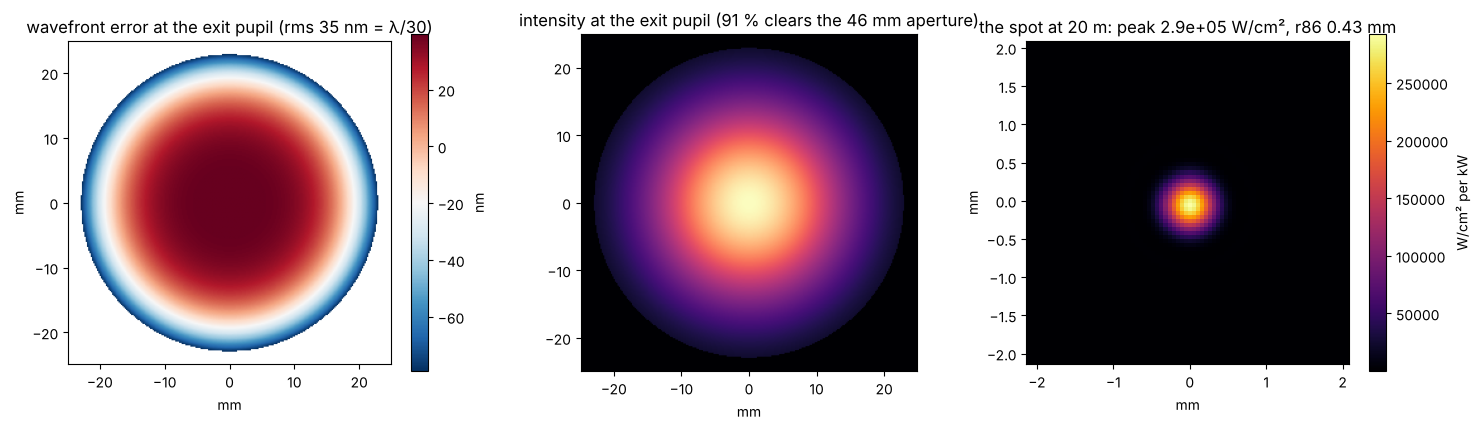

In [5]:
HEAD = ('2" lens (CA 46 mm)', 8)
g0, lay0, pw0, spot0 = SPOTS[HEAD]
REPORT["head"] = {"aperture": HEAD[0], "magnification": HEAD[1], "f1_mm": -750 / HEAD[1], "f2_mm": 750, "spacing_mm": lay0["spacing"] * 1e3, "delta_mm": lay0["delta"] * 1e3,
                  "beam_radius_at_L2_mm": pw0["w_beam"] * 1e3, "throughput": pw0["throughput"], "wavefront_rms_nm": pw0["rms_m"] * 1e9, "strehl": sr.strehl(pw0, LAM),
                  "spot_r86_mm": spot0["r86_mm"], "peak_W_cm2_per_kW": spot0["peak_W_cm2"]}
fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))
im = axs[0].imshow(pw0["W"] * 1e9, extent=np.array([pw0["x"][0], pw0["x"][-1], pw0["x"][0], pw0["x"][-1]]) * 1e3, cmap="RdBu_r"); plt.colorbar(im, ax=axs[0], label="nm")
axs[0].set(title=f"wavefront error at the exit pupil (rms {pw0['rms_m']*1e9:.0f} nm = λ/{LAM/pw0['rms_m']:.0f})", xlabel="mm", ylabel="mm")
axs[1].imshow(pw0["amp"] ** 2, extent=np.array([pw0["x"][0], pw0["x"][-1], pw0["x"][0], pw0["x"][-1]]) * 1e3, cmap="magma"); axs[1].set(title=f"intensity at the exit pupil ({100*pw0['throughput']:.0f} % clears the 46 mm aperture)", xlabel="mm")
I, x = spot0["I"], spot0["x"] * 1e3
c = len(x) // 2; s = slice(c - 40, c + 40)
im = axs[2].imshow(I[s, s] * 1e-4, extent=[x[s][0], x[s][-1], x[s][0], x[s][-1]], cmap="inferno"); plt.colorbar(im, ax=axs[2], label="W/cm² per kW")
axs[2].set(title=f"the spot at 20 m: peak {spot0['peak_W_cm2']:.2g} W/cm², r86 {spot0['r86_mm']:.2f} mm", xlabel="mm", ylabel="mm")
plt.tight_layout(); fig.savefig(OUT / "head_spot.png", dpi=110); plt.show()

### 3.2 Spherical aberration: the f-number of L2, its orientation, and what the plate can do

A plano-convex singlet focusing a collimated beam has a longitudinal spherical aberration of about $0.27\,h^2/f$ for
the marginal ray at height $h$ with its curved face toward the collimated light — and four times that the other way
round. In the expander L2 receives the *diverging* beam from L1 and sends the nearly collimated one to the target, so
**its curved face goes last, toward the target**. The negative lens L1 is overcorrected and takes a little back. The
wavefront error that matters at the target is $W = \mathrm{LSA} \cdot u^2/4$ with $u = h/f_2$: it falls as $1/f_2^3$
for a given beam, which is why the chart below is so steep.

A **plane-parallel plate of thickness $t$ in the converging (or diverging) beam** shifts the marginal focus more than
the paraxial one — it is *overcorrected*, by $t\,u^2\,(n^2-1)/(2n^3)$ — so in principle it compensates a singlet's
undercorrection. The ray trace says how far that goes.

In [6]:
rows = []
for f2 in (0.75, 0.5, 0.4, 0.3, 0.2):
    for curved_last in (True, False):
        g, lay = sr.galilean(-f2 / 8, f2, 0.0508, L=L, D_in=D_IN, positive_curved_last=curved_last)
        sa = sr.longitudinal_sa(g, D_IN)
        pw = sr.pupil_wavefront(g, D_IN, W_IN, L, D_ap=0.046)
        best = sr.best_focus(pw, LAM, L, HEAD_POWER, span=1.5, n=7) if curved_last else None
        rows.append({"f2 [mm]": f2 * 1e3, "f-number of L2": round(f2 / 0.040, 1), "L2 curved face": "last (toward target)" if curved_last else "first (toward L1)",
                     "marginal focus − paraxial, at 20 m [m]": round(sa["LSA_marginal"], 2), "wavefront rms [nm]": round(pw["rms_m"] * 1e9), "Strehl": round(sr.strehl(pw, LAM), 3),
                     "peak [W/cm² per kW]": f"{best['peak_W_cm2']:.3g}" if best else "", "spot r86 [mm]": round(best["r86_mm"], 2) if best else ""})
SA = pd.DataFrame(rows); display(SA)

# the plate against the singlet: its overcorrection in the diverging beam between L1 and L2, against L2's undercorrection
g, lay = sr.galilean(-0.75 / 8, 0.75, 0.0508, L=L, D_in=D_IN)
sa0 = sr.longitudinal_sa(g, D_IN)
rows = []
for t_mm in (0, 12, 25, 50):
    gp = sr.Train(g.surfaces[:2]) + sr.plate(t_mm * 1e-3, sr.N_UVFS, z=0.25) + sr.Train(g.surfaces[2:]) if t_mm else g
    gp, dz = sr.refocused(gp, L, D_IN)
    sa = sr.longitudinal_sa(gp, D_IN)
    pw = sr.pupil_wavefront(gp, D_IN, W_IN, L, D_ap=0.046)
    rows.append({"UVFS plate between L1 and L2 [mm]": t_mm, "L2 refocus [mm]": round(dz * 1e3, 2), "marginal − paraxial focus [m]": round(sa["LSA_marginal"], 3),
                 "change by the plate [m]": round(sa["LSA_marginal"] - sa0["LSA_marginal"], 3), "wavefront rms [nm]": round(pw["rms_m"] * 1e9), "Strehl": round(sr.strehl(pw, LAM), 3)})
PL = pd.DataFrame(rows); display(PL)
u = 0.020 / 0.75
print(f"Formula: a plate overcorrects by t·u²·(n²−1)/(2n³) = {12e-3 * u**2 * (sr.N_UVFS**2 - 1) / (2 * sr.N_UVFS**3) * 1e6:.1f} µm per 12 mm at L2's own focus (u = {u:.3f});",
      f"L2 undercorrects by about 0.27·h²/f = {0.27 * 0.020**2 / 0.75 * 1e6:.0f} µm. The plate would have to be {0.27 * 0.020**2 / 0.75 / (u**2 * (sr.N_UVFS**2 - 1) / (2 * sr.N_UVFS**3)):.1f} m thick.")
REPORT["spherical"] = {"f2_mm_vs_strehl": {int(r["f2 [mm]"]): r["Strehl"] for _, r in SA[SA["L2 curved face"].str.startswith("last")].iterrows()},
                       "wrong_orientation_strehl_f750": float(SA[(SA["f2 [mm]"] == 750) & SA["L2 curved face"].str.startswith("first")]["Strehl"].iloc[0]),
                       "plate_12mm_changes_LSA_by_m": float(PL["change by the plate [m]"].iloc[1])}

,f2 [mm],f-number of L2,L2 curved face,"marginal focus − paraxial, at 20 m [m]",wavefront rms [nm],Strehl,peak [W/cm² per kW],spot r86 [mm]
0,750.0,18.8,last (toward target),-0.39,35,0.977,2.85e+05,0.44
1,750.0,18.8,first (toward L1),-1.88,185,0.524,,
2,500.0,12.5,last (toward target),-1.19,113,0.792,2.87e+05,0.44
3,500.0,12.5,first (toward L1),-5.25,632,0.001,,
4,400.0,10.0,last (toward target),-2.18,215,0.431,2.67e+05,0.52
5,400.0,10.0,first (toward L1),-8.27,1241,0.000,,
6,300.0,7.5,last (toward target),-4.51,500,0.011,1.34e+05,1.42
7,300.0,7.5,first (toward L1),-12.61,2959,0.000,,
8,200.0,5.0,last (toward target),-10.24,1682,0.000,4.09e+04,8.64
9,200.0,5.0,first (toward L1),-17.19,10083,0.000,,


,UVFS plate between L1 and L2 [mm],L2 refocus [mm],marginal − paraxial focus [m],change by the plate [m],wavefront rms [nm],Strehl
0,0,-0.00,-0.389,-0.000,35,0.977
1,12,3.73,-0.388,0.001,35,0.977
2,25,7.77,-0.386,0.003,35,0.977
3,50,15.53,-0.383,0.006,35,0.977


Formula: a plate overcorrects by t·u²·(n²−1)/(2n³) = 1.5 µm per 12 mm at L2's own focus (u = 0.027); L2 undercorrects by about 0.27·h²/f = 144 µm. The plate would have to be 1.1 m thick.


**Verdict on spherical aberration.** At $f_2$ = 750 mm (f/19 for the 40 mm beam) the singlet is diffraction-limited
with the right orientation and still usable with the wrong one; at 500 and 400 mm the best focus still rescues most
of the peak (the spot grows to 0.5 mm) but the Strehl is gone — the margin a tilt or a thermal lens needs; at 300 mm
half the peak is lost and at 200 mm the spot is a blur, and the wrong orientation is hopeless below 750 mm. The plane-parallel plate is a **spherical-aberration trim of a few micrometres, not a cure**:
its overcorrection is two orders of magnitude short of a singlet at any useful f-number — the plate would have to be
about as thick as the lens's focal length. So the rule is *keep L2 slow* (750 mm, ≥ f/15) and oriented curved-face
toward the target; if the head must be short, buy the spherical correction (a best-form or aspheric singlet, or a
doublet) and let the plate do what it is good at, next.

### 3.3 Astigmatism: where it comes from, what it costs, and the tilted plate that cancels it

Astigmatism at the target: a longitudinal separation $\Delta z$ of the tangential and sagittal foci of L2 is a
wavefront error $W_{ast} = \Delta z \, u^2 / 2$ over the beam ($u$ = beam radius / $f_2$); the Rayleigh quarter wave
allows $\Delta z \le \lambda / (2 u^2)$ = 0.75 mm for this head. Sources: **a tilt $\varepsilon$ of L2** (a thin lens
at a field angle: $\Delta z = f_2 \varepsilon^2$ — 1.8° uses the whole budget), a cylindrical figure error of a large
lens, an elliptical beam from the source (fibre lasers are round; diode stacks are not), and a window that someone
tilted for a reason.

**A plane-parallel plate tilted by $i$ in a converging beam** moves the sagittal focus by
$\Delta_S = t\,(1 - \cos i / (n \cos i'))$ and the tangential one by $\Delta_T = t\,(1 - \cos^3 i / (n \cos^3 i'))$
with $\sin i = n \sin i'$ (Smith, *Modern Optical Engineering* §4.4): their difference,
$t\,i^2 (n^2 - 1)/n^3$ for small tilts, is astigmatism with its axis set by the tilt axis. **Tilt the plate about
the same axis as the astigmatism to cancel, by the angle $i = \sqrt{\Delta z\, n^3 / (t (n^2 - 1))}$**. The plate
also adds coma, linear in $i$ — so the *sign* of the tilt matters: one sign cancels the coma of the tilted lens too,
the other doubles it. Below: the formula against the trace, the cost of a tilted L2, then the compensation with a
12 mm UVFS window in the diverging beam between L1 and L2, L2 refocused after the plate (its focus knob).

,plate t [mm],tilt [°],"astigmatism, traced [µm]",exact formula [µm],small-angle t·i²(n²−1)/n³ [µm]
0,12,5,33.1,33.0,33.0
1,12,14,264.9,257.0,259.0
2,12,26,962.8,865.3,893.4
3,25,14,552.0,535.5,539.7


,L2 tilt [°],Δz = f2·ε² [mm],W_ast = Δz·u²/2 [nm],wavefront rms [nm],Strehl,peak [W/cm² per kW],spot r86 [mm],pointing offset [arcsec]
0,0.0,0.000,0,35,0.977,2.92e+05,0.43,0
1,0.5,0.057,20,32,0.981,2.9e+05,0.43,-6
2,1.0,0.228,81,32,0.983,2.81e+05,0.46,-12
3,2.0,0.914,325,93,0.846,2.01e+05,0.70,-24
4,3.0,2.056,731,224,0.375,8.5e+04,1.24,-36


,plate tilt [°],L2 refocus [mm],wavefront rms [nm],Strehl,peak [W/cm² per kW],spot r86 [mm],pointing offset [arcsec]
0,-34.200000,4.540000,133,0.680000,2.13e+05,0.600000,-721
1,-30.200000,4.090000,90,0.836000,2.61e+05,0.470000,-618
2,-26.300000,3.700000,58,0.928000,2.83e+05,0.440000,-524
3,-22.400000,3.360000,44,0.964000,2.82e+05,0.440000,-437
4,-18.400000,3.080000,49,0.960000,2.68e+05,0.480000,-357
5,-13.100000,2.790000,67,0.926000,2.42e+05,0.550000,-256
6,0.000000,2.430000,94,0.846000,2.01e+05,0.700000,-24
7,13.100000,2.540000,78,0.878000,2.1e+05,0.680000,208
8,18.400000,2.730000,60,0.916000,2.26e+05,0.650000,308
9,22.400000,2.920000,45,0.940000,2.38e+05,0.600000,389


L2 tilted 2.0°: the formula asks for the 12 mm plate at ±26.3°; the trace finds the best spot at -26.3° (Strehl 0.93, peak 2.83e+05 W/cm² per kW, against 2.01e+05 uncorrected and 2.92e+05 with no tilt).


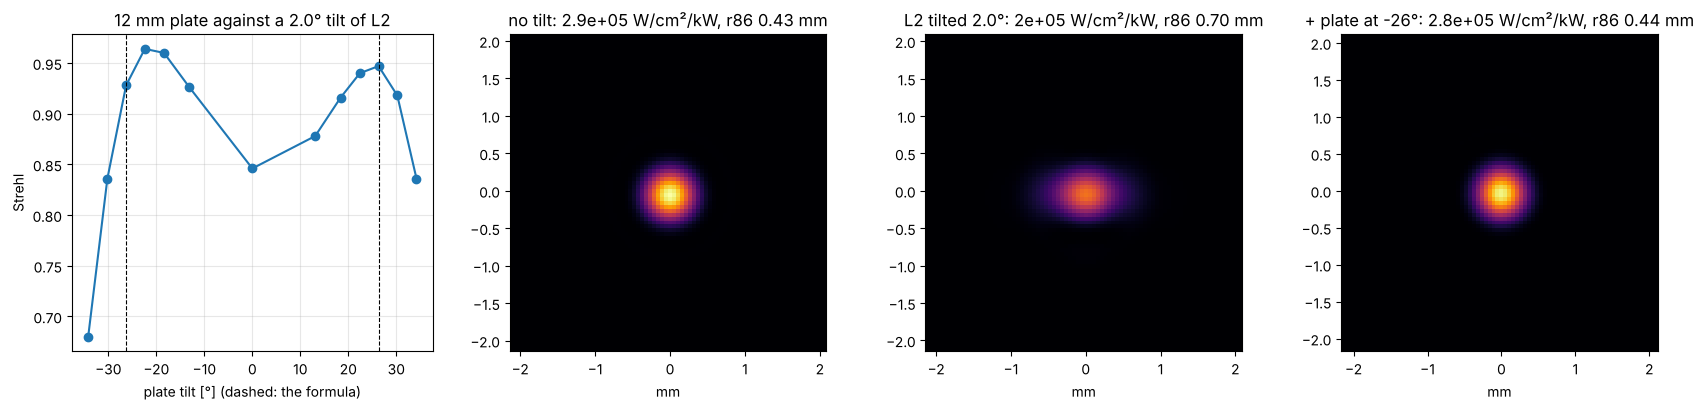

In [7]:
# the formula against the ray trace, on a single lens with a tilted plate in its converging beam
lens1 = sr.lens(0.75, 0.0508, sr.N_BK7)
rows = []
for t_mm, deg in ((12, 5), (12, 14), (12, 26), (25, 14)):
    tr = lens1 + sr.plate(t_mm * 1e-3, sr.N_UVFS, z=0.1, tilt=np.radians(deg))
    a = sr.astigmatism(tr, 0.046); f = sr.plate_shifts(t_mm * 1e-3, sr.N_UVFS, np.radians(deg))
    rows.append({"plate t [mm]": t_mm, "tilt [°]": deg, "astigmatism, traced [µm]": round(a["astigmatism"] * 1e6, 1), "exact formula [µm]": round(f["astigmatism"] * 1e6, 1),
                 "small-angle t·i²(n²−1)/n³ [µm]": round(f["small_angle"] * 1e6, 1)})
display(pd.DataFrame(rows))

# the cost of a tilted L2 in the head, and the plate that cancels it
g, lay = sr.galilean(-0.75 / 8, 0.75, 0.0508, L=L, D_in=D_IN)
zL2 = g.surfaces[2].V[2]
L1 = sr.Train(g.surfaces[:2])
def head_case(train):
    train, dz = sr.refocused(train, L, D_IN)
    pw = sr.pupil_wavefront(train, D_IN, W_IN, L, D_ap=0.046)
    r = sr.psf(pw, LAM, L, HEAD_POWER, defocus=-0.25)
    return pw, r, dz
rows, PSFS = [], {}
for eps in (0.0, 0.5, 1.0, 2.0, 3.0):
    L2t = sr.tilt_train(sr.Train(g.surfaces[2:]), np.radians(eps), zL2)
    pw, r, dz = head_case(L1 + L2t)
    PSFS[eps] = r
    rows.append({"L2 tilt [°]": eps, "Δz = f2·ε² [mm]": round(0.75 * np.radians(eps) ** 2 * 1e3, 3), "W_ast = Δz·u²/2 [nm]": round(0.75 * np.radians(eps) ** 2 * (0.020 / 0.75) ** 2 / 2 * 1e9),
                 "wavefront rms [nm]": round(pw["rms_m"] * 1e9), "Strehl": round(sr.strehl(pw, LAM), 3), "peak [W/cm² per kW]": f"{r['peak_W_cm2']:.3g}", "spot r86 [mm]": round(r["r86_mm"], 2),
                 "pointing offset [arcsec]": round(np.degrees(pw["pointing_rad"][1]) * 3600)})
TILT = pd.DataFrame(rows); display(TILT)

EPS, T_PLATE = 2.0, 12e-3
L2t = sr.tilt_train(sr.Train(g.surfaces[2:]), np.radians(EPS), zL2)
i_pred = sr.plate_tilt_for(0.75 * np.radians(EPS) ** 2, T_PLATE, sr.N_UVFS)
tilts = np.concatenate([-np.degrees(i_pred) * np.array([1.3, 1.15, 1.0, 0.85, 0.7, 0.5]), [0.0], np.degrees(i_pred) * np.array([0.5, 0.7, 0.85, 1.0, 1.15, 1.3])])
rows, best_c = [], None
for deg in tilts:
    tr = L1 + sr.plate(T_PLATE, sr.N_UVFS, z=0.25, tilt=np.radians(deg)) + L2t
    pw, r, dz = head_case(tr)
    rows.append({"plate tilt [°]": round(deg, 1), "L2 refocus [mm]": round(dz * 1e3, 2), "wavefront rms [nm]": round(pw["rms_m"] * 1e9), "Strehl": round(sr.strehl(pw, LAM), 3),
                 "peak [W/cm² per kW]": r["peak_W_cm2"], "spot r86 [mm]": round(r["r86_mm"], 2), "pointing offset [arcsec]": round(np.degrees(pw["pointing_rad"][1]) * 3600)})
    if best_c is None or r["peak_W_cm2"] > best_c[1]["peak_W_cm2"]:
        best_c = (deg, r, pw)
COMP = pd.DataFrame(rows); display(COMP.style.format({"peak [W/cm² per kW]": "{:.3g}"}))
print(f"L2 tilted {EPS}°: the formula asks for the 12 mm plate at ±{np.degrees(i_pred):.1f}°; the trace finds the best spot at {best_c[0]:.1f}° "
      f"(Strehl {sr.strehl(best_c[2], LAM):.2f}, peak {best_c[1]['peak_W_cm2']:.3g} W/cm² per kW, against {PSFS[EPS]['peak_W_cm2']:.3g} uncorrected and {PSFS[0.0]['peak_W_cm2']:.3g} with no tilt).")
REPORT["astigmatism"] = {"L2_tilt_deg_vs_strehl": {float(r["L2 tilt [°]"]): r["Strehl"] for _, r in TILT.iterrows()}, "demo_L2_tilt_deg": EPS, "plate_t_mm": T_PLATE * 1e3,
                         "plate_tilt_formula_deg": float(np.degrees(i_pred)), "plate_tilt_best_deg": float(best_c[0]), "strehl_uncorrected": float(TILT[TILT["L2 tilt [°]"] == EPS]["Strehl"].iloc[0]),
                         "strehl_corrected": float(sr.strehl(best_c[2], LAM)), "peak_recovered_fraction": float(best_c[1]["peak_W_cm2"] / PSFS[0.0]["peak_W_cm2"])}

fig, axs = plt.subplots(1, 4, figsize=(17, 4.2))
axs[0].plot(COMP["plate tilt [°]"], COMP["Strehl"], "o-"); axs[0].axvline(np.degrees(i_pred), color="k", ls="--", lw=0.8); axs[0].axvline(-np.degrees(i_pred), color="k", ls="--", lw=0.8)
axs[0].set(xlabel="plate tilt [°] (dashed: the formula)", ylabel="Strehl", title=f"12 mm plate against a {EPS}° tilt of L2"); axs[0].grid(alpha=0.3)
for ax_, (label, r) in zip(axs[1:], [("no tilt", PSFS[0.0]), (f"L2 tilted {EPS}°", PSFS[EPS]), (f"+ plate at {best_c[0]:.0f}°", best_c[1])]):
    x = r["x"] * 1e3; c = len(x) // 2; s = slice(c - 40, c + 40)
    ax_.imshow(r["I"][s, s] * 1e-4, extent=[x[s][0], x[s][-1], x[s][0], x[s][-1]], cmap="inferno", vmin=0, vmax=PSFS[0.0]["peak_W_cm2"])
    ax_.set(title=f"{label}: {r['peak_W_cm2']:.2g} W/cm²/kW, r86 {r['r86_mm']:.2f} mm", xlabel="mm")
plt.tight_layout(); fig.savefig(OUT / "astigmatism_plate.png", dpi=110); plt.show()

**Verdict on astigmatism.** The formula's tilt is the traced optimum, and the sign that also cancels the coma brings
the spot back to within a few percent of the untilted head (a 2° tilt of L2 costs a third of the peak; the plate
recovers it). The plate costs a refocus of a few millimetres (the knob)
and a pointing offset of a few arc minutes (the steering mirror absorbs it; it is fixed, not a jitter). This is the
plate's real job in a kilowatt head: a **12 mm UVFS window on a tilt stage between L1 and L2**, set once on the spot
camera against whatever astigmatism the head came with — lens tilt, a cylindrical figure error, or an elliptical
source. Tilt it about the astigmatism's own axis; try both signs and keep the one with the rounder spot.

## 4. The weld: 2 heads and 10 heads on steel

Rosenthal's moving point source, $T - T_0 = \dfrac{q}{2\pi k R}\, e^{-v(R + x)/2\kappa}$ with the absorbed power
$q = A \cdot P$ (steel absorbs about 35 % at 1 µm while solid, far more once a keyhole forms), gives the melt pool in
conduction mode; the keyhole regime is read off the power density alone. The speed $v$ is the speed of the spot over
the part — the machine's own motion the heads fail to track, plus the weld's advance.

,heads,power [kW],peak density [W/cm²],regime,speed [mm/s],pool width [mm],pool length [mm],pool depth (conduction) [mm]
0,1,1.0,2.9e+05,conduction,5,1.7,1.75,0.80
1,1,1.0,2.9e+05,conduction,10,1.4,1.60,0.70
2,1,1.0,2.9e+05,conduction,20,1.2,1.45,0.55
3,2,2.0,5.8e+05,conduction,5,2.9,3.20,1.40
4,2,2.0,5.8e+05,conduction,10,2.4,2.90,1.10
5,2,2.0,5.8e+05,conduction,20,1.9,2.65,0.80
6,4,4.0,1.2e+06,keyhole,5,4.9,5.90,2.25
7,4,4.0,1.2e+06,keyhole,10,3.9,5.35,1.65
8,4,4.0,1.2e+06,keyhole,20,3.0,4.95,1.15
9,10,10.0,2.9e+06,keyhole,5,9.0,10.55,3.70


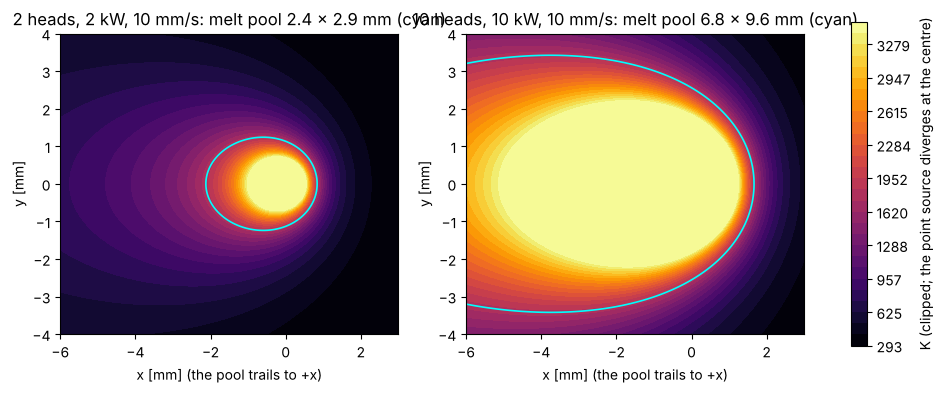

Two heads make a conduction weld (a 2 mm wide, 1 mm deep pool); ten heads are three times over the keyhole threshold — the weld of a 10 kW machine.


In [8]:
head_peak = spot0["peak_W_cm2"]            # per head, W/cm², from §3.1
rows, POOLS = [], {}
for n in (1, 2, 4, 10):
    for v_mm_s in (5, 10, 20):
        P = n * HEAD_POWER
        pool = sr.rosenthal(sr.STEEL, sr.STEEL.absorptivity * P, v_mm_s * 1e-3)
        I = n * head_peak
        POOLS[(n, v_mm_s)] = pool
        rows.append({"heads": n, "power [kW]": P / 1e3, "peak density [W/cm²]": f"{I:.2g}", "regime": "keyhole" if I >= sr.KEYHOLE_W_CM2 else ("conduction" if I >= 1e5 else "heating only"),
                     "speed [mm/s]": v_mm_s, "pool width [mm]": round(pool["width_mm"], 2), "pool length [mm]": round(pool["length_mm"], 2), "pool depth (conduction) [mm]": round(pool["depth_mm"], 2)})
WELD = pd.DataFrame(rows); display(WELD)
REPORT["weld"] = {"steel_absorptivity": sr.STEEL.absorptivity, "rows": WELD.to_dict("records")}

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for ax_, n in zip(axs, (2, 10)):
    pool = POOLS[(n, 10)]
    T = pool["T"]; x = pool["x_mm"]
    im = ax_.contourf(x, x, np.clip(T, 293, 3500), levels=np.linspace(293, 3500, 30), cmap="inferno")
    ax_.contour(x, x, T, levels=[sr.STEEL.T_melt], colors="cyan", linewidths=1.2)
    ax_.set(title=f"{n} heads, {n} kW, 10 mm/s: melt pool {pool['width_mm']:.1f} × {pool['length_mm']:.1f} mm (cyan)", xlabel="x [mm] (the pool trails to +x)", ylabel="y [mm]", xlim=(-6, 3), ylim=(-4, 4), aspect="equal")
plt.colorbar(im, ax=axs, label="K (clipped; the point source diverges at the centre)"); fig.savefig(OUT / "weld_pool.png", dpi=110); plt.show()
print("Two heads make a conduction weld (a 2 mm wide, 1 mm deep pool); ten heads are three times over the keyhole threshold — the weld of a 10 kW machine.")

## 5. Many heads at one point — and a target that moves

Each head is a tube about 80 mm across. N of them sit on the smallest ring that seats them, all aimed at the one
point 20 m away. The ring is the catch: **the beams cross, they do not run together**. Move the target along the line
of sight by $\Delta z$ and the spots of a ring of radius $R$ walk apart by $\Delta z \cdot R / L$. The depth of focus of
one beam ($z_R$ = 0.4 m) is generous; the crossing is not: for the spots to stay within a third of their radius of each
other, $\Delta z \le w_0 L / (3R)$ — centimetres. And sideways, every head must point within $w_0 / (3L)$ of the
common point: **about 7 µrad, 1.4 arc seconds** — the pointing of a laser tracker, not of a welding head. Both
numbers are the price of the standoff: twenty metres multiply every angle.

A moving machine then means a **tracking loop**: a camera (or a retro-reflector and a position-sensing detector) on
each head, the steering mirror closing the loop at a few hundred hertz, the lens spacing (the focus knob) following
the measured range. What the loop leaves behind, the pointing residual $\sigma$, decides the power density the
target actually sees — N spots that do not overlap are N conduction welds side by side, not one keyhole. The Monte
Carlo below lands N copies of the traced spot with independent Gaussian pointing errors and reads the peak.

,heads,ring radius [m],incidence at the target [°],footprint stretch,axial tolerance Δz [mm],pointing tolerance per head [µrad],as arc seconds,lateral motion for 1 ms of loop delay at 0.3 m/s [mm]
0,2,0.050,0.14,1.0,57.5,7.2,1.5,0.3
1,10,0.162,0.46,1.0,17.8,7.2,1.5,0.3


,heads,pointing σ per head [µrad],σ at the target [mm],"peak, all aligned [W/cm²]","peak, mean [W/cm²]","peak, 10th percentile [W/cm²]",regime (p10)
0,2,0.0,0.00,5.8e+05,5.8e+05,5.8e+05,conduction
1,2,3.0,0.06,5.8e+05,5.6e+05,5.5e+05,conduction
2,2,6.0,0.12,5.8e+05,5.2e+05,4.5e+05,conduction
3,2,10.0,0.20,5.8e+05,4.4e+05,3e+05,conduction
4,2,20.0,0.40,5.8e+05,3.5e+05,2.9e+05,conduction
5,2,40.0,0.80,5.8e+05,3.1e+05,2.9e+05,conduction
6,10,0.0,0.00,2.9e+06,2.9e+06,2.9e+06,keyhole
7,10,3.0,0.06,2.9e+06,2.7e+06,2.7e+06,keyhole
8,10,6.0,0.12,2.9e+06,2.3e+06,2.2e+06,keyhole
9,10,10.0,0.20,2.9e+06,1.8e+06,1.5e+06,keyhole


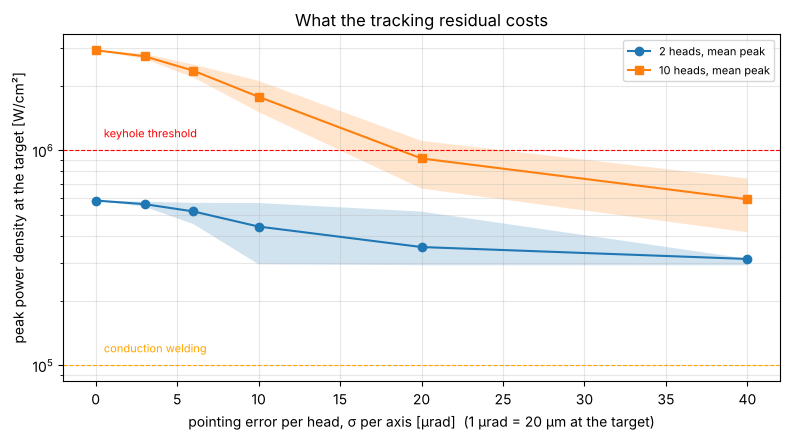

In [9]:
w0 = spot0["r86_mm"] * 1e-3
rows = []
for n in (2, 10):
    ring = sr.ring_layout(n, 0.080)
    cr = sr.crossing(ring["ring_radius_m"], L, w0)
    rows.append({"heads": n, "ring radius [m]": round(ring["ring_radius_m"], 3), "incidence at the target [°]": round(cr["incidence_deg"], 2), "footprint stretch": round(cr["footprint_stretch"], 4),
                 "axial tolerance Δz [mm]": round(cr["axial_tolerance_m"] * 1e3, 1), "pointing tolerance per head [µrad]": round(cr["pointing_tolerance_urad"], 1),
                 "as arc seconds": round(cr["pointing_tolerance_urad"] * 0.206, 1), "lateral motion for 1 ms of loop delay at 0.3 m/s [mm]": 0.3})
RING = pd.DataFrame(rows); display(RING)

rng = np.random.default_rng(7)
sigmas = np.array([0, 3, 6, 10, 20, 40]) * 1e-6
rows, MC = [], {}
for n in (2, 10):
    for sg in sigmas:
        s = sr.sum_of_spots(spot0, n, sg, L, rng=rng, trials=40)
        MC[(n, sg)] = s
        rows.append({"heads": n, "pointing σ per head [µrad]": sg * 1e6, "σ at the target [mm]": round(sg * L * 1e3, 2), "peak, all aligned [W/cm²]": f"{s['peak_aligned_W_cm2']:.2g}",
                     "peak, mean [W/cm²]": f"{s['peak_mean_W_cm2']:.2g}", "peak, 10th percentile [W/cm²]": f"{s['peak_p10_W_cm2']:.2g}",
                     "regime (p10)": "keyhole" if s["peak_p10_W_cm2"] >= sr.KEYHOLE_W_CM2 else ("conduction" if s["peak_p10_W_cm2"] >= 1e5 else "heating only")})
POINT = pd.DataFrame(rows); display(POINT)
REPORT["many_heads"] = {"ring": RING.to_dict("records"), "pointing_monte_carlo": POINT.to_dict("records")}

fig, ax = plt.subplots(figsize=(8, 4.5))
for n, mk in ((2, "o-"), (10, "s-")):
    ax.plot(sigmas * 1e6, [MC[(n, s)]["peak_mean_W_cm2"] for s in sigmas], mk, label=f"{n} heads, mean peak")
    ax.fill_between(sigmas * 1e6, [MC[(n, s)]["peak_p10_W_cm2"] for s in sigmas], [MC[(n, s)]["peak_p90_W_cm2"] for s in sigmas], alpha=0.2)
ax.axhline(sr.KEYHOLE_W_CM2, color="r", ls="--", lw=0.8); ax.text(0.5, 1.15e6, "keyhole threshold", color="r", fontsize=8)
ax.axhline(1e5, color="orange", ls="--", lw=0.8); ax.text(0.5, 1.15e5, "conduction welding", color="orange", fontsize=8)
ax.set(xlabel="pointing error per head, σ per axis [µrad]  (1 µrad = 20 µm at the target)", ylabel="peak power density at the target [W/cm²]", yscale="log", title="What the tracking residual costs")
ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8); plt.tight_layout(); fig.savefig(OUT / "pointing.png", dpi=110); plt.show()

**The verdict on many heads.** With every head pointed to 3 µrad the ten beams add up to a keyhole with margin; at
10 µrad per head the sum is still a keyhole, but with half the peak and a thin margin; at 20 µrad it is a wide
conduction pool and at 40 µrad a scatter of separate heating marks. Two heads lose less in proportion (there is
less to lose) and stay in conduction welding at any of these errors. A ring of ten heads 0.15 m in radius also needs the target's range held to
about ±2 cm while it welds. The spot, the optics and the plate are not the hard part of this machine: **the
tracking is** — 3 µrad at a few hundred hertz on a target that moves.

## 6. Stray beams and shielding

Every beam that is not absorbed in the pool goes somewhere at 20 m. Three kinds: **a miss** (the target moved, the
beam carries on past the focus and re-expands along the cone it came in on, $w \approx w_0 + w_{in} d / L$ — one
kilowatt that is 0.4 mm wide at the focus is still 5 mm wide 5 m beyond it), **the specular reflection** off the
pool (solid steel reflects ~65 % at 1 µm; the pool surface curves, so the reflection spreads at least as fast as the
incoming cone — the same table scaled by 0.65, in a direction set by the surface), and **the diffuse scatter** of the
pool (Lambertian, ~35 % of the power — harmless to metal at any distance, an eye hazard for tens of metres). The
heads themselves see the specular return head-on when the surface is normal: that is what the tilted plate and the
laser's own isolator are for.

A shield sheet holds when its steady peak temperature rise under the beam, $\Delta T = A P / (\sqrt{2\pi}\, k\, w)$
(a Gaussian source on a half space; lateral conduction is all the cooling), stays below what the material takes; when
it does not, the thin-sheet heating rate gives the time to failure, $t = \rho c \delta \Delta T_{allow} / (A I_0)$.
Three candidate shields, like the other Svarog cases: aluminium (reflects 90 % — a mirror, so the reflection needs
catching), steel (absorbs, conducts poorly), and black polycarbonate (clear PC is transparent at 1 µm and shields
nothing).

In [10]:
w0 = spot0["r86_mm"] * 1e-3
rows = []
for sh in sr.SHIELDS:
    for d in (1.0, 5.0, 20.0):
        for n in (1, 10):
            w = sr.stray_radius(pw0["w_beam"], L, d, w0)
            r = sr.shield_response(sh, n * HEAD_POWER, w)      # n heads overlapping: the worst case near the focus, where they still cross
            if n == 10 and d > 1.0:
                continue                                        # beyond a metre the ten beams have separated (ring radius 0.15 m at 20 m)
            rows.append({"shield": sh.name, "beams on it": n, "m past the focus": d, "beam radius there [mm]": round(w * 1e3, 1), "I0 [W/cm²]": f"{r['I0_W_cm2']:.3g}",
                         "steady ΔT [K]": f"{r['dT_steady_K']:.3g}", "allowed ΔT [K]": sh.dT_allow, "holds": bool(r["holds"]), "else time to the limit [s]": round(r["t_to_limit_s"], 2), "note": sh.note})
SHIELD = pd.DataFrame(rows); display(SHIELD)
mpe = 10.0                                                      # W/m²: the order of the CW maximum permissible exposure at 1070 nm (ANSI Z136.1; check the standard for the exposure time)
nhd = {n: sr.diffuse_hazard_distance(n * HEAD_POWER, 0.35, mpe) for n in (2, 10)}
spec = sr.shield_response(sr.SHIELDS[0], 0.65 * HEAD_POWER, sr.stray_radius(pw0["w_beam"], L, 5.0, w0))
print(f"Diffuse scatter: an eye hazard to {nhd[2]:.0f} m for 2 heads and {nhd[10]:.0f} m for 10 (MPE taken as {mpe} W/m²); the specular return of one head 5 m from the pool heats aluminium by {spec['dT_steady_K']:.0f} K.")
REPORT["shielding"] = {"rows": SHIELD.to_dict("records"), "diffuse_hazard_m": nhd}

,shield,beams on it,m past the focus,beam radius there [mm],I0 [W/cm²],steady ΔT [K],allowed ΔT [K],holds,else time to the limit [s],note
0,aluminium sheet 3 mm,1,1.0,1.5,2.93e+04,159,250.0,True,0.06,reflects 90 %: the reflection must be caught too
1,aluminium sheet 3 mm,10,1.0,1.5,2.93e+05,1.59e+03,250.0,False,0.01,reflects 90 %: the reflection must be caught too
2,aluminium sheet 3 mm,1,5.0,5.6,2e+03,114,250.0,True,0.91,reflects 90 %: the reflection must be caught too
3,aluminium sheet 3 mm,1,20.0,21.3,141,72.2,250.0,True,12.95,reflects 90 %: the reflection must be caught too
4,steel sheet 3 mm,1,1.0,1.5,2.93e+04,2.71e+03,500.0,False,0.06,"absorbs most, conducts little: hot spots"
5,steel sheet 3 mm,10,1.0,1.5,2.93e+05,2.71e+04,500.0,False,0.01,"absorbs most, conducts little: hot spots"
6,steel sheet 3 mm,1,5.0,5.6,2e+03,1.51e+03,500.0,False,0.84,"absorbs most, conducts little: hot spots"
7,steel sheet 3 mm,1,20.0,21.3,141,808,500.0,False,11.87,"absorbs most, conducts little: hot spots"
8,"polycarbonate 5 mm, black",1,1.0,1.5,2.93e+04,1.22e+06,100.0,False,0.00,softens at 150 °C; clear PC is no shield (transparent at 1 µm)
9,"polycarbonate 5 mm, black",10,1.0,1.5,2.93e+05,1.22e+07,100.0,False,0.00,softens at 150 °C; clear PC is no shield (transparent at 1 µm)


Diffuse scatter: an eye hazard to 5 m for 2 heads and 11 m for 10 (MPE taken as 10.0 W/m²); the specular return of one head 5 m from the pool heats aluminium by 74 K.


### 6.1 The shield matrix: 1, 3 and 5 mm at 20, 50, 100 and 200 m past the focus

Far from the focus the beams have long separated (one beam per shield) and a sheet is thin against the beam, so the
thin-plate steady state decides: radial conduction to the rim over the length $\ell = \sqrt{k\delta/2h}$ before
convection and radiation ($h$ ≈ 15 W/m²K per face) take the heat, or — when the beam is wider than $\ell$, as it is
here — the surface cap $\Delta T = A I_0 / 2h$, which no thickness helps. Thickness buys *time* (the adiabatic
heating of the sheet) and conduction length; it does not change what a wide beam does to a surface that cannot shed
the heat.

m past the focus                20.0     50.0     100.0   200.0
shield        thickness [mm]                                   
aluminium     1.0               165.0     81.0     47.0    47.0
              3.0                72.0     44.0     22.0    16.0
              5.0                48.0     31.0     18.0     9.0
polycarbonate 1.0             84417.0  34183.0  17162.0  8599.0
              3.0             84417.0  34183.0  17162.0  8599.0
              5.0             84417.0  34183.0  17162.0  8599.0
steel         1.0              1550.0    796.0    679.0   170.0
              3.0               808.0    328.0    265.0   170.0
              5.0               566.0    278.0    159.0   159.0

m past the focus              20.0   50.0   100.0  200.0
shield        thickness [mm]                            
aluminium     1.0              True   True   True   True
              3.0              True   True   True   True
              5.0              True   True   True   True
polycarbonate 1.0             False  False  False  False
              3.0             False  False  False  False
              5.0             False  False  False  False
steel         1.0             False  False  False   True
              3.0             False   True   True   True
              5.0             False   True   True   True

m past the focus              20.0   50.0   100.0   200.0
shield        thickness [mm]                             
aluminium     1.0               4.3   26.3  104.4   416.0
              3.0              12.9   79.0  313.3  1247.9
              5.0              21.6  131.6  522.1  2079.8
polycarbonate 1.0               0.1    0.7    2.9    11.4
              3.0               0.4    2.2    8.6    34.2
              5.0               0.6    3.6   14.3    57.1
steel         1.0               4.0   24.1   95.8   381.5
              3.0              11.9   72.4  287.3  1144.4
              5.0              19.8  120.7  478.8  1907.4

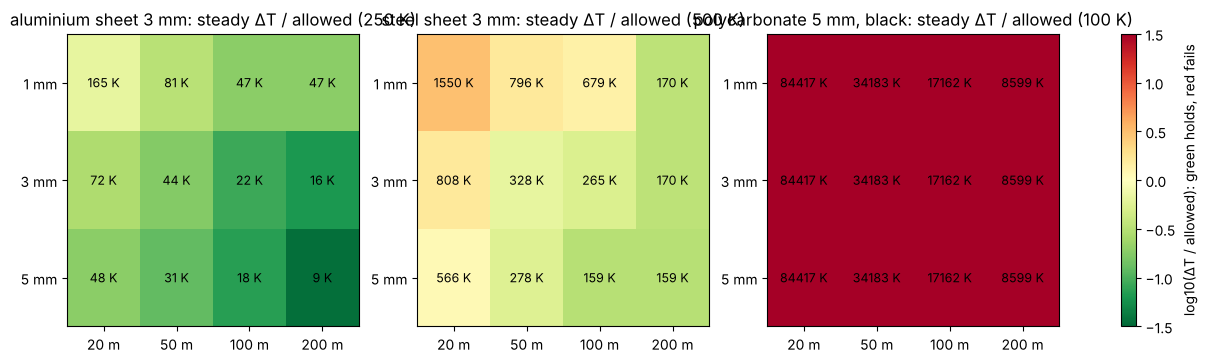

In [11]:
THICK = (1e-3, 3e-3, 5e-3); DIST = (20.0, 50.0, 100.0, 200.0)
rows = []
for sh in sr.SHIELDS:
    for d in DIST:
        w = sr.stray_radius(pw0["w_beam"], L, d, w0)
        for t in THICK:
            r = sr.shield_response(sh, HEAD_POWER, w, thickness=t)
            rows.append({"shield": sh.name.split(" sheet")[0].split(" 5 mm")[0], "thickness [mm]": t * 1e3, "m past the focus": d, "beam radius [mm]": round(w * 1e3), "I0 [W/cm²]": round(r["I0_W_cm2"], 2),
                         "ΔT half space [K]": round(r["dT_half_space_K"]), "ΔT thin plate [K]": round(r["dT_thin_plate_K"]), "steady ΔT [K]": round(r["dT_steady_K"]), "allowed [K]": sh.dT_allow,
                         "holds": bool(r["holds"]), "else seconds to the limit": round(r["t_to_limit_s"], 1)})
MATRIX = pd.DataFrame(rows)
display(MATRIX.pivot_table(index=["shield", "thickness [mm]"], columns="m past the focus", values="steady ΔT [K]").round(0))
display(MATRIX.pivot_table(index=["shield", "thickness [mm]"], columns="m past the focus", values="holds", aggfunc="first"))
display(MATRIX.pivot_table(index=["shield", "thickness [mm]"], columns="m past the focus", values="else seconds to the limit").round(1))
REPORT["shield_matrix"] = MATRIX.to_dict("records")

fig, axs = plt.subplots(1, 3, figsize=(16, 3.8))
for ax_, sh in zip(axs, sr.SHIELDS):
    name = sh.name.split(" sheet")[0].split(" 5 mm")[0]
    sub = MATRIX[MATRIX["shield"] == name].pivot(index="thickness [mm]", columns="m past the focus", values="steady ΔT [K]")
    im = ax_.imshow(np.log10(sub.values / sh.dT_allow), cmap="RdYlGn_r", vmin=-1.5, vmax=1.5, aspect="auto")
    ax_.set(xticks=range(len(DIST)), xticklabels=[f"{d:.0f} m" for d in DIST], yticks=range(len(THICK)), yticklabels=[f"{t*1e3:.0f} mm" for t in THICK], title=f"{sh.name}: steady ΔT / allowed ({sh.dT_allow:.0f} K)")
    for i in range(len(THICK)):
        for j in range(len(DIST)):
            ax_.text(j, i, f"{sub.values[i, j]:.0f} K", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=axs, label="log10(ΔT / allowed): green holds, red fails"); fig.savefig(OUT / "shield_matrix.png", dpi=110); plt.show()

**Shielding verdict.** Behind the target, an **aluminium sheet** holds at any distance against a single stray beam
(at a metre past the focus it is the ten crossing beams together that burn through it, and there they have not yet
separated) — but it is a mirror: back it with a matt, water-cooled aluminium
dump angled to throw its reflection into a baffle, not back toward the heads. **Steel** holds only when the beam has
spread to centimetres (20 m past the focus); nearer, it melts through in under a second: it is the enclosure wall,
not the dump. **Black polycarbonate** fails everywhere a raw beam lands (seconds at best) and is only for the diffuse
scatter and the enclosure's windows — in the 1 µm-rated laser-safety grade, never clear PC. Enclose the whole 20 m
path; the diffuse scatter alone is an eye hazard at 10 m.

The matrix says the rest: against a stray kilowatt beam 20 m or more past the focus, **aluminium holds at 1, 3 and
5 mm** (165 K at the worst corner, 1 mm at 20 m — and it reflects 90 % of the beam onward); **steel holds from 50 m
at 3 and 5 mm**, at 1 mm only at 200 m, and at 20 m melts through at any thickness within 4–20 s — its surface
cannot shed what it absorbs; **polycarbonate never holds**: even at 200 m a 5 mm black sheet softens in about a
minute. Thickness buys seconds, not safety; distance and reflectivity do.

## 7. The parts

Stock optics that fit the head of §3, with the thing to check on the vendor's page before ordering (catalogue
numbers move; the design does not). Kilowatt CW through N-BK7 makes a thermal lens — the UVFS versions of the same
lenses are the ones to buy. The alternative to the refracting L2 is an off-axis parabola: no spherical aberration on
axis, no thermal lens, but the stock ones are f/4 and alignment-critical, and a 3" one costs more than the lenses.

In [12]:
PARTS = pd.DataFrame(sr.PARTS)
display(PARTS)
cost_head = PARTS[PARTS["role"].str.startswith(("L2, positive, 2", "L1", "compensator plate", "steering", "laser"))]["price_eur"].sum() - PARTS[PARTS["role"] == "compensator plate, large"]["price_eur"].sum()
print(f"Rough cost of one head (laser, L1, L2 2\", plate, steering mirror): {cost_head:,.0f} EUR → 2 heads {2 * cost_head:,.0f} EUR, 10 heads {10 * cost_head:,.0f} EUR, before the tracking sensors and the mounts.")
REPORT["cost_per_head_eur"] = float(cost_head)

,role,part,spec,price_eur,verify
0,"L2, positive, 2""",Thorlabs LA1727-C,"N-BK7 plano-convex Ø50.8 mm f = 750 mm, AR 1050–1700 nm",90,clear aperture (~46 mm); swap for a UVFS LA4xxx-C at kilowatt CW (thermal lens)
1,"L2, positive, 3""","Edmund 75 mm Ø PCX (NIR coat), f 500–750 mm",N-BK7 or UVFS plano-convex Ø75 mm,250,which focal lengths are stocked in Ø75 mm; UVFS version
2,"L1, negative, 1""",Thorlabs LC1258-C,"N-BK7 plano-concave Ø25.4 mm f = −75 mm, AR 1050–1700 nm",60,the exact f (−75 mm) and the C coating; UVFS LC4xxx-C
3,compensator plate,Thorlabs WG42012 / WG41050 class,"UVFS window Ø50.8 mm, t = 8–12 mm, λ/10, <5 arcsec",150,"thickness stocked in Ø2"" (8 mm, 12 mm) and the C coating"
4,"compensator plate, large",Edmund #54-229,"UVFS window Ø150 mm, t = 15 mm, λ/10, <10 arcsec, uncoated",900,AR coating at 1070 nm (uncoated loses 7 % and returns it to the laser)
5,focusing mirror (alternative),Thorlabs MPD3124 class,"Ø3"" off-axis parabola, RFL 12"" (305 mm), protected silver",1100,"no SA on axis, no thermal lens, but a 305 mm RFL means f/4: alignment-critical"
6,steering,"fast steering mirror Ø2"" (PI S-331 / Optotune MR-E-2 class)","±25 mrad, ~1 kHz, µrad resolution",4000,"aperture (the 40–50 mm beam), coating for kW at 1070 nm, resolution < 10 µrad"
7,laser,IPG YLR-1000-SM,"1 kW CW, 1070 nm, M² < 1.1, HLC-8, 5 mm collimator",35000,collimator options; a 14 µm-fibre Raycus/MAX single-mode source is the cheaper equivalent


Rough cost of one head (laser, L1, L2 2", plate, steering mirror): 39,300 EUR → 2 heads 78,600 EUR, 10 heads 393,000 EUR, before the tracking sensors and the mounts.


## 8. Verdict

- **Welding at 20 m is optically possible** with single-mode kilowatt fibre lasers and 2–3 inch stock optics: one
  head makes a 0.43 mm (r86) spot and 3 × 10⁵ W/cm² per kilowatt at the target. Multimode sources need 6-inch
  optics; diode stacks cannot do it.
- **Spherical aberration** is solved by the f-number: keep L2 at 750 mm (≥ f/15) with its curved face toward the
  target. The plane-parallel plate trims it by micrometres and cannot cure a fast singlet.
- **Astigmatism** is where the plate earns its place: a 12 mm UVFS window on a tilt stage between L1 and L2, tilted
  about the astigmatism's axis by the formula's angle (and the sign that cancels the coma too), brings a head
  astigmatic enough to lose a third of its peak back to within a few percent of perfect.
- **2 heads: a conduction weld** (2 mm wide, 1 mm deep at 10 mm/s on steel). **10 heads: a keyhole weld** — but only
  if every head points to better than 10 µrad (3 µrad for margin) and the range is held to ±2 cm.
- **Shielding**: an aluminium dump behind the target (its reflection baffled), steel for the enclosure walls, black
  laser-grade polycarbonate for windows only; the whole path enclosed.
- **The hard part is the tracking**, not the optics: 20 m multiplies every angle. Next: the tracking loop (sensor,
  steering mirror, range) as its own study, and a bench test of one head on a static target at 20 m.

In [13]:
REPORT["elapsed_s"] = round(time.time() - T_START, 1)
path = Path("designs/data/svarog_remote.json"); path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(json.dumps(REPORT, indent=1, default=float))
print(f"written {path} ({REPORT['elapsed_s']} s of computing)")
STAMPS = GATE.leave()
print(f"{len(STAMPS)} output(s) stamped")

written designs/data/svarog_remote.json (141.3 s of computing)
1 output(s) stamped
